In [ ]:
# Pandas is most commonly used for data wrangling and data manipulation purposes
# NumPy is a fundamental library for numerical computing in Python.Mathematical Operations, Arrays,Linear Algebra etc
#Removing Duplicates
#Fixing NULL values(Age, Department)
#Standardization of each value(Gender)
#Concatenate First Name and Last Name
#Add a new column(YearsAtCompany)
#STrength by Maritial Status

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
pd.set_option('display.max_rows', None)
df = pd.read_csv("Sample_HR.csv")

# df=df.shape[0]
# print('No of rows:',df)
# df=df[df.duplicated()].shape[0]
df=df.drop_duplicates()
Average_Age=df['Age'].mean()
Average_Age=int(Average_Age)

df['Age']=df['Age'].fillna(Average_Age)
df['Department']=df['Department'].fillna('Data Engineering')
df['Gender']=df['Gender'].replace({'M':'Male','F':'Female'})
# df=df[df['Department']=='Data Engineering']
df['Full Name']=df['First Name'] + ' ' + df['Last Name']


columns = df.columns.tolist()
last_name_index = columns.index('Last Name')
last_name_index
columns.insert(last_name_index + 1, columns.pop(columns.index('Full Name')))
df = df[columns]

# Get the no of experience
hire_date = pd.to_datetime(df['Hire_Date']).dt.year
# hire_date
current_year = datetime.now().year
df['YearsAtCompany'] = current_year-hire_date
df.head(1)

,Employee_ID,First Name,Last Name,Full Name,Gender,MaritalStatus,Department,Grade,Employee_Count,Job_Satisfaction,...,MonthlyRate,Age,Job Type,Job Experience,Hire_Date,Company_Environment,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,Country
0,1,Shelia,Mahoney,Shelia Mahoney,Male,Single,Sales,2,1,4,...,19479,41.0,Permannent,16,1/1/2010,5,0,1,16,United Kingdom


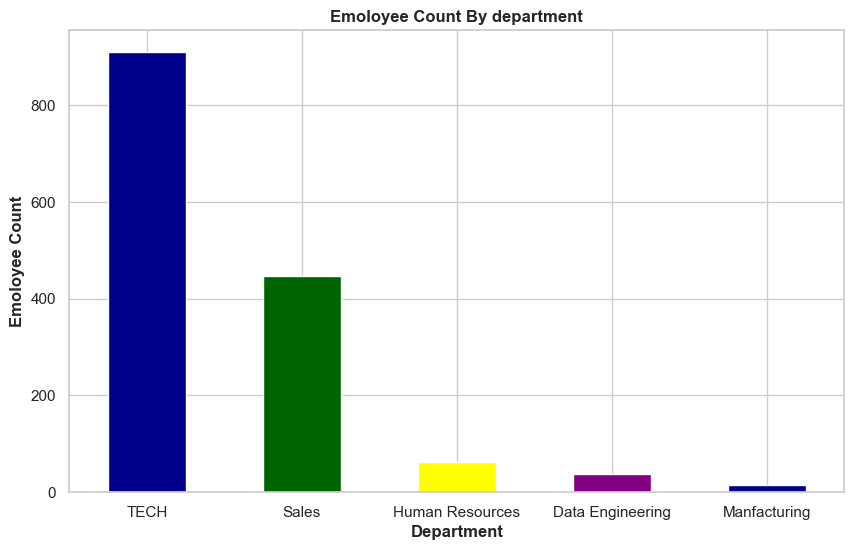

In [12]:
#Create a Bar Chart
"""The department-wise employee distribution helps identify which departments have the highest and lowest workforce. 
This analysis can help HR understand how employees are distributed across departments
and identify areas that may require workforce planning."""
department_count=df['Department'].value_counts()
plt.figure(figsize=(10,6))
color=['darkblue','darkgreen','yellow','purple']
department_count.plot(kind='bar',color=color)
plt.title('Emoloyee Count By department',fontweight='bold')
plt.xlabel('Department',fontweight='bold')
plt.ylabel('Emoloyee Count',fontweight='bold')
plt.xticks(rotation=0)
plt.show()


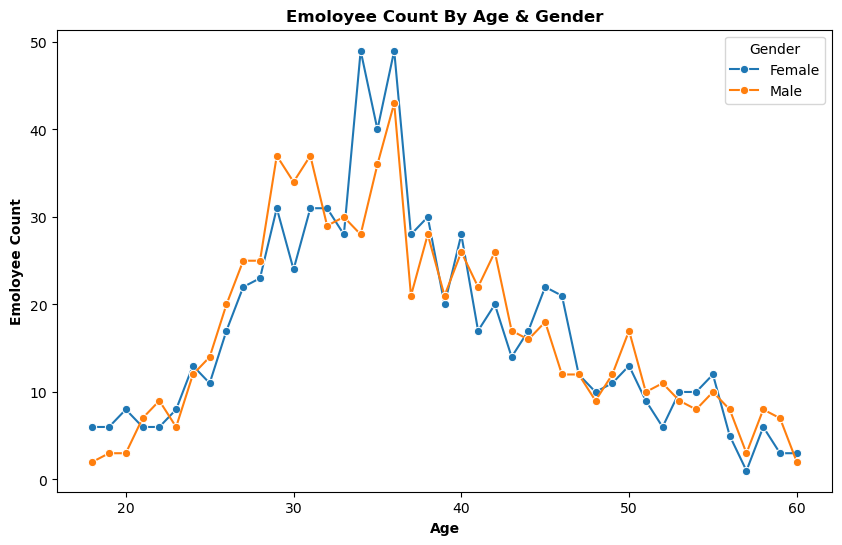

In [5]:
#Line Chart
"""The age-wise and gender-wise analysis shows how employees are distributed across different age groups. 
Comparing the two gender groups can help HR understand workforce demographics and identify differences in age distribution."""
age_gender=df.groupby(['Age','Gender']).size().reset_index(name='Count')
age_gender
plt.figure(figsize=(10,6))
sns.lineplot(data=age_gender, x='Age', y='Count', hue='Gender', marker='o')
plt.title('Emoloyee Count By Age & Gender',fontweight='bold')
plt.xlabel('Age',fontweight='bold')
plt.ylabel('Emoloyee Count',fontweight='bold')
plt.xticks(rotation=0)
plt.show()

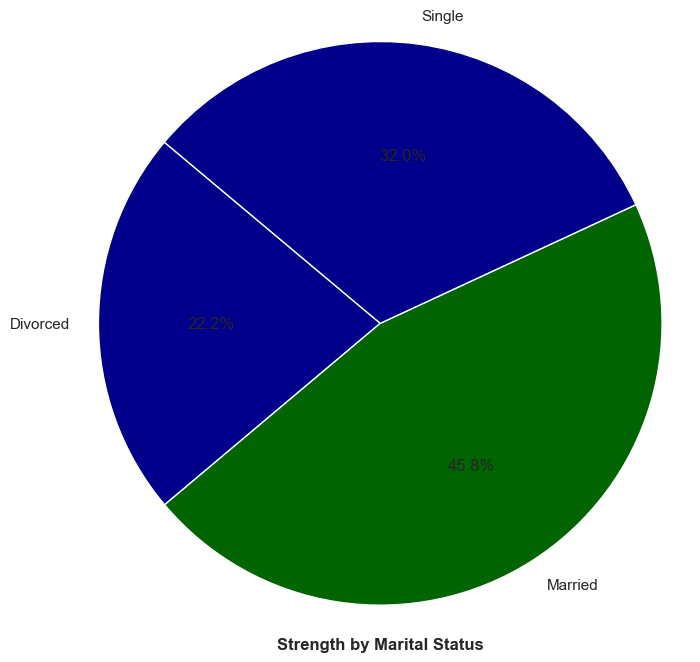

In [7]:
"""The marital-status distribution provides an overview of the workforce by marital status.
This demographic analysis can help HR understand employee composition and support broader workforce planning."""
Marital_Status_count=df.groupby(['MaritalStatus']).size().reset_index(name='Count')
Marital_Status=Marital_Status_count['MaritalStatus']
Count= Marital_Status_count['Count']

sns.set(style="whitegrid")
colors = sns.color_palette("colorblind")[0:len(Marital_Status)]
colors=['darkblue','darkgreen']
plt.figure(figsize=(8, 8))
plt.pie(Count, labels=Marital_Status, colors=colors, autopct='%1.1f%%', startangle=140)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.xlabel('Strength by Marital Status',fontweight='bold')
plt.show()

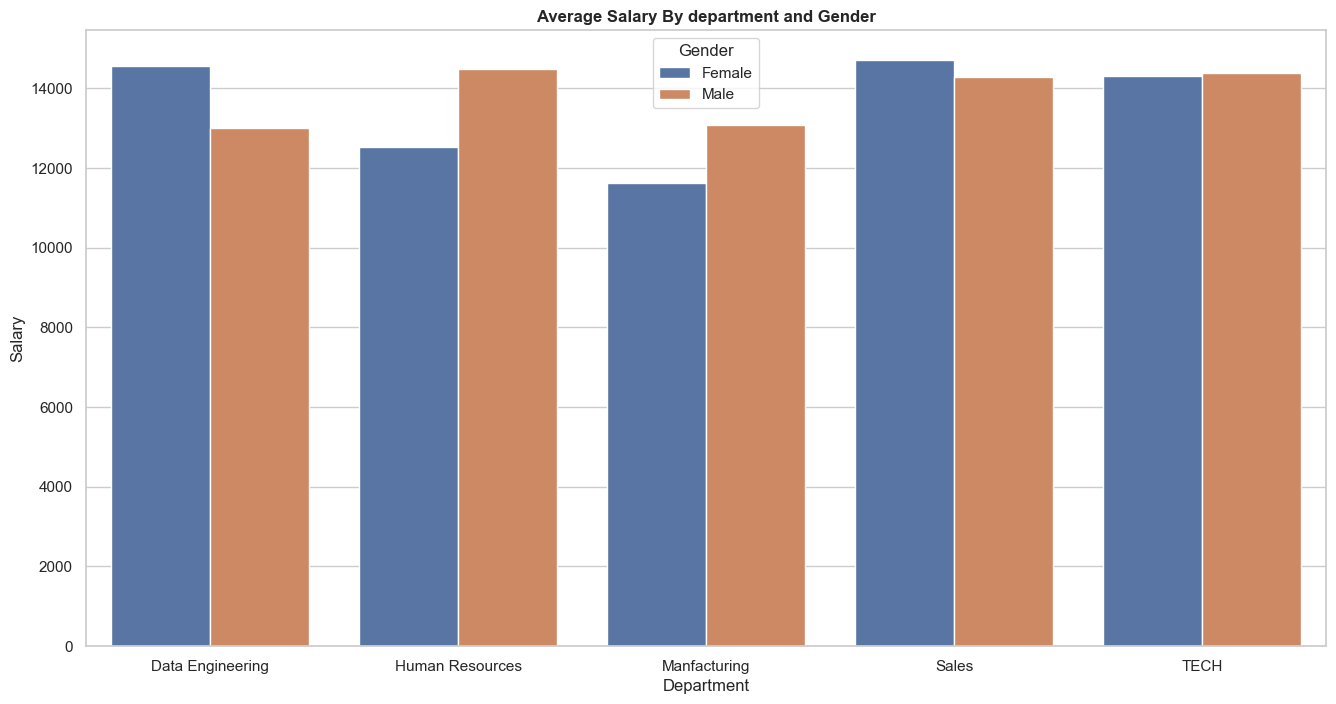

In [13]:
"""The department-wise salary comparison highlights differences in average recorded pay across departments and gender groups. 
These results can help identify areas for further compensation analysis.
Any apparent gender differences should be investigated further, taking job roles, experience, and other relevant factors into account."""
df=df.rename(columns={'MonthlyRate':'Salary'})
average_Salary=df.groupby(['Department','Gender'])['Salary'].mean().reset_index()
plt.figure(figsize=(16, 8))
sns.barplot(data=average_Salary, x='Department', y='Salary', hue='Gender')
plt.title('Average Salary By department and Gender',fontweight='bold')
plt.show()

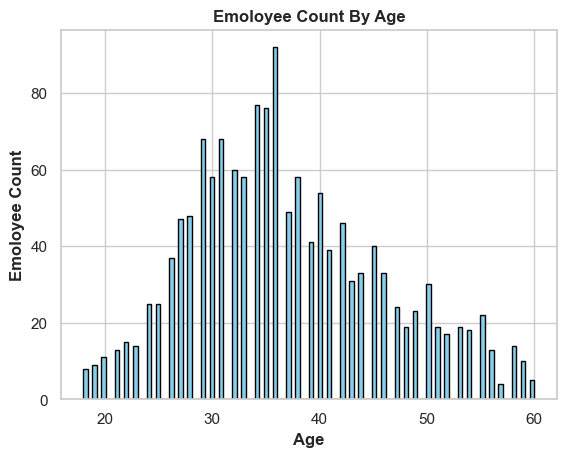

In [9]:
"""The age distribution histogram shows how employee records are spread across different ages. 
The concentration of observations indicates the age ranges represented most frequently in the dataset, 
while less populated ranges may indicate smaller workforce segments."""
age=df['Age']
plt.hist(age, bins=100, edgecolor='black',color='skyblue')
plt.title('Emoloyee Count By Age',fontweight='bold')
plt.xlabel('Age',fontweight='bold')
plt.ylabel('Emoloyee Count',fontweight='bold')
plt.show()



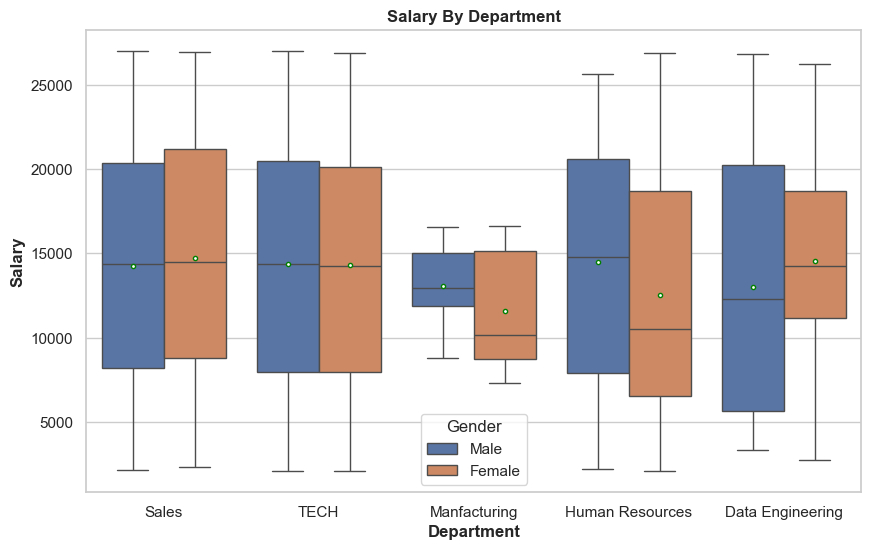

In [10]:
"""The box plot helps compare salary distributions across departments and gender groups. 
It highlights differences in medians, variability, and potential outliers. 
These patterns can guide further investigation into compensation structures and pay consistency."""
# ,showmeans='True',meanprops={"marker":"o"
#                                                                                   ,"markerfacecolor":"white"
#                                                                                   ,"markersize":"6"
#                                                                                   ,"markeredgecolor":"green"}
plt.figure(figsize=(10, 6))
sns.boxplot(x='Department', y='Salary', data=df,hue='Gender',showmeans='True',meanprops={"marker":"o"
                                                                                  ,"markerfacecolor":"white"
                                                                                  ,"markersize":"3"
                                                                                  ,"markeredgecolor":"green"})
plt.title('Salary By Department',fontweight='bold')
plt.xlabel('Department',fontweight='bold')
plt.ylabel('Salary',fontweight='bold')
plt.show()

In [15]:
"""Conclusion
The department-wise employee distribution helps identify which departments have the highest and lowest workforce. 
This information can support HR workforce planning.
"""

'Conclusion\nThe department-wise employee distribution helps identify which departments have the highest and lowest workforce. \nThis information can support HR workforce planning.\n'